## Dati come immagini

### Introduzione

Supponiamo di avere di fronte un foglio quadrettato, avere a disposizione una tavolozza di pastelli
e che un vostro amico vi chieda di ritrarre sul foglio, al meglio delle vostre possibilità, un certo fiore;
tuttavia, impone una condizione: ogni casella del foglio dovrà essere colorata unicamente da un singolo pastello a vostra scelta.

Ecco cosa potremmo aspettarci che accada:

![](immagini_sorgente/fig1_2.png)

Il processo di conversione di un immagine da analogica a digitale è concettualmente simile all'esempio di cui sopra.
Infatti, se si è stati in grado di colorare ogni singola cella del foglio quadrettato, con un unico colore di una certa sfumatura ed intensità, ottendo
un buon risultato; allora, si sarà anche in grado di definire una matrice, delle stesse dimensioni della griglia sul foglio, i cui coefficienti (in qualche modo)
rappresentino la sfumatura e l'intensità luminosa del colore utilizzato per riempire il corrispondente quadretto sul foglio.

In sostanza, ogni immagine digitale di $M \times N$ pixel, informaticamente parlando, non è altro che una matrice di dimensioni $M \times N$ ed i suoi coefficienti, ai fatti, rappresentano quali sfumature di colore verrano mostrate e in quale posizione. 

Per esempio, nel caso di immagini in scala di grigi, ogni pixel dell'immagine
conterrà solo sfumature di grigio. Per convenzione, la matrice corrispettiva ad un immagine del genere,
avrà come coefficienti soltanto valori interi da un minimo di 0 ad un massimo di 255;
dove: 0 rappresenta il colore nero e 255 rappresenta il colore bianco. 

Invece, poichè un immagine a colori è ottenuta tramite la sovrapposizione di
tre rappresentazioni della stessa immagine: una in scala di rossi, una in scala di verdi ed una in scala di blu; sarà quindi richiesto che il colore di ogni pixel di questa immagine sia rappresentato da vettore di tre valori, ciascuno per ogni intesità del colore rosso, verde e blu.

Minimo assoluto: 0
Massimo assoluto: 229


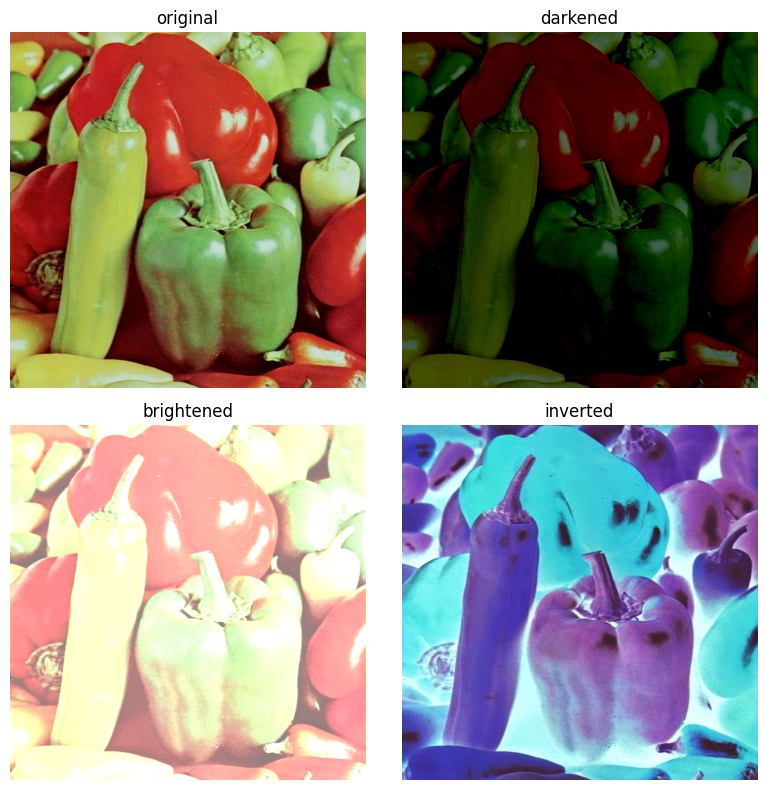

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Leggi l'immagine: i canali sono già in ordine RGB
img = plt.imread("immagini_sorgente/peppers1.tif")

print(f"Minimo assoluto: {np.min(img)}")
print(f"Massimo assoluto: {np.max(img)}")

# Converti in float e normalizza se l'immagine ha valori interi
if np.issubdtype(img.dtype, np.integer):
    img2 = img.astype(np.float32) / np.iinfo(img.dtype).max
else:
    img2 = img.astype(np.float32)  # Si assumono valori già in [0, 1]

plt.figure(figsize=(8, 8))

plt.subplot(221)
plt.imshow(img2)
plt.title("original")
plt.axis("off")

plt.subplot(222)
img_d = np.clip(img2 - 0.5, 0, 1)
plt.imshow(img_d)
plt.title("darkened")
plt.axis("off")

plt.subplot(223)
img_b = np.clip(img2 + 0.5, 0, 1)
plt.imshow(img_b)
plt.title("brightened")
plt.axis("off")

plt.subplot(224)
plt.imshow(1 - img2)
plt.title("inverted")
plt.axis("off")

plt.tight_layout()
plt.show()

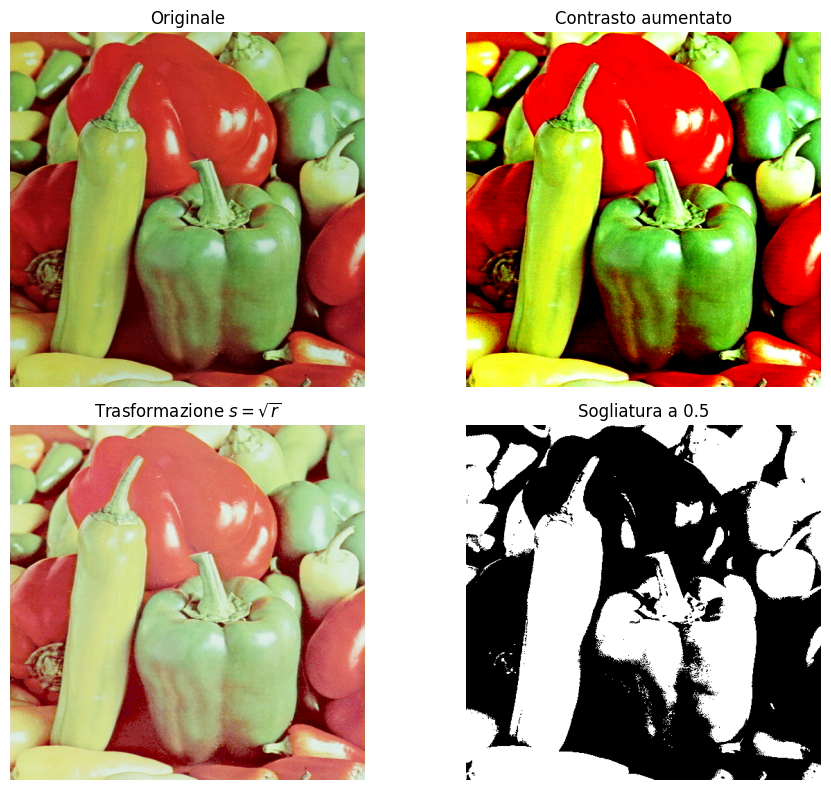

In [2]:
# Aumento del contrasto rispetto al livello intermedio 0.5
img_contrasto = np.clip(0.5 + 2 * (img2 - 0.5), 0, 1)

# Trasformazione non lineare: schiarisce soprattutto i valori bassi
img_gamma = img2**0.5

# Conversione da RGB a scala di grigi
img_grigia = (
    0.2126 * img2[:, :, 0]
    + 0.7152 * img2[:, :, 1]
    + 0.0722 * img2[:, :, 2]
)

# Sogliatura: ogni pixel diventa bianco oppure nero
img_binaria = (img_grigia >= 0.5).astype(float)

fig, axes = plt.subplots(2, 2, figsize=(10, 8))

immagini = [img2, img_contrasto, img_gamma, img_binaria]
titoli = [
    "Originale",
    "Contrasto aumentato",
    r"Trasformazione $s=\sqrt{r}$",
    "Sogliatura a 0.5"
]

for ax, immagine, titolo in zip(axes.ravel(), immagini, titoli):
    ax.imshow(immagine, cmap="gray", vmin=0, vmax=1)
    ax.set_title(titolo)
    ax.axis("off")

plt.tight_layout()
plt.show()

Queste trasformazioni calcolano ogni pixel di uscita usando soltanto il pixel corrispondente; la convoluzione combina invece i valori di un intorno.

### Convoluzione

In generale, la convoluzione è
un'operazione matematica (simbolo: *)
che, date due funzioni, ne produce una
terza che è calcolata come segue:

$$
 (f*g)(t)=\int{f(\tau)g(t-\tau)d\tau}
 $$

Nell'imaging, $f$ e $g$ sono funzioni discrete bidimensionali, cioè 
matrici,corrispondenti ad immagini.
La convoluzione discreta 2D diventa quindi:

$$
(f*g)(x,y)=\sum_{i=0}^M \sum_{j=1}^N f(x,y) g(x-i,y-j), \ \ x,y=0, \ldots N
$$ 

L'applicazione delle convoluzioni in imaging
può essere più facilmente spiegata
graficamente come segue:

- consideriamo una matrice $K$ di dimensione  nxn (di solito n è dispari) il cui punto centrale viene fatto coincidere con un pixel dell'immagine $f$ a cui applicare la convoluzione
- moltiplichiamo i valori nella matrice con i valori dei
pixel corrispondenti, e sommiamo tutti i risultati
- ll valore ottenuto è il valore del pixel centrale nel
risultato
- l'operazione viene ripetuta (spostando la matrice)
per tutti i pixel dell'immagine


All'interno del contesto di questa definizione, la matrice $K$ prenderà il nome di **nucleo di convoluzione** o **kernel di convoluzione**

![](immagini_sorgente/conv.png)

### Pratica guida alla convoluzione di immagini

Mostriamo un esempio di come applicare le definizioni sinora presentate.

In primo luogo, come già evidenziato precedentemente, un immagine non è altro che una matrice (di qualche dimensione) i cui coefficienti rappresentato l'intensità di uno o più colori.

Dunque, assumiamo che la seguente immagine:

![alt-text](immagini_sorgente/bc_zero_cropped.png)

sia la nostra matrice $A$.

E supponiamo che la seguente matrice, sia il nostro nucleo di convoluzione $K$:

![alt-text](immagini_sorgente/fig103_ker.png)

Adesso dobbiamo scegliere come estendere la matrice $A$. Ecco alcune opzioni:

![alt-text](immagini_sorgente/cond_bordo.png)

tutti i diversi modi di estendere diversamente la matrice $A$ prendono il nome di: **condizioni al bordo**.


**ATTENZIONE**: la matrice $A$ ha dimensioni $503 \times 503$ e $K$ ha dimensioni $3 \times 3$, quindi ci occorre un estensione di $A$ di dimensioni $503 + (3-1) \times (503 + (3-1)$.
Ne segue, che le estensioni mostrate hanno dimensioni **ben più estese di quanto dovrebbero!** Sono solo da considerarsi come esempi utili di diverse condizioni al bordo. 

<!---**Attenzione**: la funzione di convoluzione $[K * (\cdot) \; | \; \mathcal{P}]$ **può** essere una funzione lineare. Vale a dire che **per delle opportune scelte del pattern di estensione $\mathcal{P}$**
potrà essere vero che, $\forall \; \alpha,\beta \in \mathbb{R}$:

$$ [K * (\alpha \; X + \beta \; Y) \; | \; \mathcal{P}] = \alpha \; [K * X \; | \; \mathcal{P}] + \beta \; [K * Y \; | \; \mathcal{P}] $$

di qui in avanti, si assumerà che qualunque sia il pattern di estensione $\mathcal{P}$ renda sempre la funzione di convoluzione lineare.---!>

<!---**Osservazione**: Poichè abbiamo presupposto che $[K * (\cdot) \; | \; \mathcal{P}]$ sia una funzione lineare. Allora, sappiamo che esiste un **unica** matrice $T$ di dimensioni $(N*M) \times (N*M)$, tale che:

$$T \, \mathcal{L}(X) = \mathcal{L}( \; [K * X \; | \; \mathcal{P}] \; )$$---!>

![alt text](immagini_sorgente/fig100_2.png)

In questo caso, il kernel utilizzato sostituisce il valore di ogni pixel con la media aritmetica dei valori contenuti nei quattro pixel ad esso adiacenti.

Ottenendo il seguente effetto di sfocatura:

![alt text](immagini_sorgente/fig103.png)

Consideriamo ora il seguente kernel:

![alt text](immagini_sorgente/kernel_bordi.png)

Osserviamo che, poichè la somma dei coefficienti è 0, sappiamo che se un pixel ha approssimativamente lo stesso colore dei quattro che
gli sono adiacenti, allora verrà rimpiazzato da un valore prossimo a zero; in altre parole, il pixer divverà di colore nero.

Ne segue che tutti e soli i pixel che avranno un valore non nullo, saranno quelli posizionati in mezzo a due regioni di colori contrastanti.
Pertanto, questo è un filtro che evidenzia i bordi dell'immagine

![alt text](immagini_sorgente/fig104.png)

Cosa succede infine se il filtro aumenta di dimensione?

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import convolve2d

dimensioni = [3, 7, 15]

fig, axes = plt.subplots(1, 4, figsize=(16, 5))

axes[0].imshow(img2)
axes[0].set_title("Originale")
axes[0].axis("off")

for ax, n in zip(axes[1:], dimensioni):

    # Kernel di media: la somma dei coefficienti è 1
    K = np.ones((n, n)) / n**2

    # Applica la convoluzione separatamente ai tre canali RGB
    img_filtrata = np.stack([
        convolve2d(
            img2[:, :, c],
            K,
            mode="same",       # Mantiene le dimensioni dell'immagine
            boundary="symm"     # Estensione simmetrica ai bordi
        )
        for c in range(3)
    ], axis=-1)

    ax.imshow(np.clip(img_filtrata, 0, 1))
    ax.set_title(f"Filtro di media {n} × {n}")
    ax.axis("off")

plt.tight_layout()
plt.show()

ImportError: cannot import name '_spropack' from 'scipy.sparse.linalg._propack' (/opt/anaconda3/envs/libro/lib/python3.13/site-packages/scipy/sparse/linalg/_propack.cpython-313-darwin.so)

## Effetto della dimensione del filtro di media

Ogni filtro sostituisce il valore di un pixel con la **media dei valori in un intorno di $n \times n$ pixel**, separatamente per ciascun canale RGB. Il kernel è:

$$
K=\frac{1}{n^2}
\begin{pmatrix}
1 & \cdots & 1\\
\vdots & \ddots & \vdots\\
1 & \cdots & 1
\end{pmatrix}.
$$

Confrontando filtri di dimensione $3 \times 3$, $7 \times 7$ e $15 \times 15$, si osserva che, all'aumentare della dimensione del filtro, la media coinvolge pixel più lontani: **la sfocatura aumenta, i piccoli dettagli scompaiono e i contorni diventano meno netti**.

Il fattore $1/n^2$ mantiene la somma dei pesi uguale a $1$, preservando le intensità nelle regioni uniformi. In prossimità dei bordi, il risultato dipende anche dalla condizione al bordo scelta; nell'esempio si utilizza un'estensione simmetrica.


# Sistemi di formazione dell'immagine

In tempi recenti, siamo tutti abituati ad avere nelle nostre tasche fotocamere che, in una frazione di secondo, sono in grado di rappresentare
in maniera più che realistica la maggior parte del mondo che ci circonda.

L'enorme diffusione di questa tecnologia può portare, erroneamente, a credere che il processo di conversione di un immagine da analogica a digitale, sia relativamente semplice:
basta avere un foto-sensore, esporlo a della luce, leggere i voltaggi delle correnti risultati e convertire questi valori in una matrice di pixel, no?

Per iniziare, supponiamo di voler fotografare una singola fonte luminosa puntiforme (per esempio, una stella della volta celeste) ed osserviamo
cosa succederebbe se seguissimo questa procedura intuitiva .






quindi, di seguito, troviamo l'oggetto che vorremmo rappresentare:

![alt text](immagini_sorgente/fig26_bis.png)


mentre questa è l'immagine ottenuta:

![alt text](immagini_sorgente/fig26.png)

come possiamo notare, anzichè avere un immagine con piccolo gruppo di pixel chiari circondati tutti  pixel scuri, l'immagine ottenuta è più simile ad una macchia
centrata nel punto in cui avremmo dovuto vedere la nostra fonte luminosa puntiforme.

Questo fenomeno di 'allargamento' delle fonti luminose puntiformi è del tutto **deterministico** e specificatamente legato all'apparecchiatura
utilizzata per catturare l'immagine.

Matematicamente, possiamo modellizzare il fenomeno così: definiamo una funzione $\mathcal{A}$ che operi come illustrato:

![alt text](immagini_sorgente/psf.png)
![alt text](immagini_sorgente/fig25.jpg)



questa funzione $\mathcal{A}$ prenderà il nome di **Point Spread Function (PSF)**. Un ottima proprietà che molti sistemi di formazione di immagini possiedono, è che la 'forma' della macchia ottenuta
in seguito all'allargamento **NON** dipende dalla posizione della fonte luminosa puntiforme. Per questa ragione, questi sistemi sono denominati **spazio invarianti**.
Altrimenti detto, la PSF **è la stessa** per tutte le possibili posizioni della fonte luminosa puntiforme all'interno dell'immagine.

![alt text](immagini_sorgente/fig27.jpg)

Ad essere più precisi, se $x$ è un immagine che rappresenta perfettamente il nostro oggetto originale e $\mathcal{A}$ è la nostra PSF, avremo che:

$$\mathcal{A}(x) = [K * x \; | \; \mathcal{P}]$$

dove $K$ è un qualche kernel di convoluzione e $\mathcal{P}$ è un pattern di estensione.

Fino a questo punto, sono state descritte fonti **deterministiche** di errore nella rappresentazione di oggetti.
Chiaramente, queste non sono le sole. Infatti, nel corso dell'acquisizione dell'immagine fenomeni aleatori e sostanzialmente imprevedibili danneggiano ulteriormente la nitidezza dell'immagine ottenuta.

Definiamo ora, un immagine $w$ i cui valori dei pixel siano stati selezionati aleatoriamente, secondo la distribuzione del *rumore Gaussiano bianco*.

A questo punto, possiamo fornire un modello matematico **discreto** che spieghi come si sia formata l'immagine $g$ (quella restituita dal nostro sistema di formazione di immagini), a partire da $x$, l'immagine che rappresenta veramente l'oggetto:

$$y^{\delta} = \mathcal{A}(x) + w = [K * x \; | \; \mathcal{P}] + w$$

dove $K$ è un qualche kernel di convoluzione, $\mathcal{P}$ è un pattern di estensione, $w$ è il medesimo di cui sopra e $\mathcal{A}$ è la point spread function.

![alt-text](immagini_sorgente/fig28.jpg)
![alt-text](immagini_sorgente/fig24.jpg)

Più esplicitamente, sapremo:

- $y^{\delta}$, l'immagine sfuocata (dal sistema di formazione di immagini) e rumorosa (a causa di aleatorie fonti d'errore);
- $\mathcal{A}(\cdot)$, la PSF legata al nostro sistema di formazione di immagini;

Dovremo ricavare $x$, l'immagine originaria.

![alt-text](immagini_sorgente/pb_inversi.png)